# U.S. Recession Forecasting — Modeling

This notebook evaluates whether engineered macroeconomic features can predict U.S. recession status six months ahead.

The notebook keeps the analysis, plots, and interpretation visible, while reusable model definitions and evaluation utilities are stored in `src/models.py` and `src/evaluation.py`.


In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Allow imports from the project root when this notebook is run from notebooks/
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from src.models import (
    build_baseline_model,
    build_logistic_model,
    build_random_forest_model,
    build_xgboost_model,
)
from src.evaluation import evaluate_model, time_series_cv, summarize_cv


## 1. Load the Engineered Dataset


In [2]:
df = pd.read_csv(
    "../data/processed/recession_features_6m.csv",
    index_col=0,
    parse_dates=True
)

df.head()


,unemployment_rate,fed_funds_rate,yield_spread_10y_2y,yield_spread_10y_3m,consumer_sentiment,credit_spread,unemployment_change_3m,unemployment_change_6m,unemployment_change_12m,initial_claims,...,industrial_production_growth_12m,housing_starts_change_3m,housing_starts_change_12m,consumer_sentiment_change_3m,consumer_sentiment_change_6m,yield_curve_inverted_10y_2y,yield_curve_inverted_10y_3m,credit_spread_change_3m,credit_spread_change_6m,target
1987-01-01,6.6,6.43,0.858500,1.506500,90.4,2.642500,-0.4,-0.4,-0.1,345600.0,...,0.610066,5.532421,-10.040568,-5.2,-7.3,0,0,-0.167045,-0.218864,0.0
1987-02-01,6.6,6.10,0.852632,1.499474,90.2,2.402632,-0.3,-0.3,-0.6,348750.0,...,2.656765,9.919901,-3.463203,-1.2,-4.7,0,0,-0.409591,-0.613559,0.0
1987-03-01,6.6,6.13,0.824091,1.482727,90.8,2.361364,0.0,-0.4,-0.6,333250.0,...,3.542961,-5.837425,-7.995736,1.7,-1.1,0,0,-0.498182,-0.392922,0.0
1987-04-01,6.3,6.37,0.998571,2.207143,92.8,2.020476,-0.3,-0.7,-0.8,336250.0,...,4.049323,-9.019166,-16.502845,2.4,-2.8,0,0,-0.622024,-0.789069,0.0
1987-05-01,6.3,6.85,0.851500,2.766500,91.1,1.900000,-0.3,-0.6,-0.9,331000.0,...,4.552761,-8.744395,-12.189860,0.9,-0.3,0,0,-0.502632,-0.912222,0.0


In [3]:
print("Shape:", df.shape)
print("Period:", df.index.min().date(), "to", df.index.max().date())
df["target"].value_counts()


Shape: (469, 24)
Period: 1987-01-01 to 2026-02-01


target
0.0    433
1.0     36
Name: count, dtype: int64

## 2. Chronological Train/Test Split

A chronological holdout set is used rather than a random split. The final portion of the time series is reserved for testing so that model evaluation more closely resembles forecasting future observations from past data.

Time-series cross-validation will also be used later because a single holdout period contains relatively few recession observations.


In [4]:
X = df.drop(columns="target")
y = df["target"].astype(int)

split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training period:", X_train.index.min().date(), "to", X_train.index.max().date())
print("Test period:", X_test.index.min().date(), "to", X_test.index.max().date())
print()
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print()
print("Training target distribution:")
print(y_train.value_counts())
print()
print("Test target distribution:")
print(y_test.value_counts())


Training period: 1987-01-01 to 2018-03-01
Test period: 2018-04-01 to 2026-02-01

Training observations: 375
Test observations: 94

Training target distribution:
target
0    341
1     34
Name: count, dtype: int64

Test target distribution:
target
0    92
1     2
Name: count, dtype: int64


The split is deliberately not shuffled. Every observation in the test set occurs after every observation in the training set.


## 3. Evaluation Metrics

Because recession months are rare, accuracy can be misleading. Models are evaluated using accuracy, precision, recall, F1, ROC-AUC, and PR-AUC. The reusable `evaluate_model()` implementation is imported from `src/evaluation.py`.


The evaluation function is kept in `src/evaluation.py` so the same metric definitions can be reused consistently across the project.


## 4. Baseline Model

A dummy classifier provides a reference point. It always predicts the most frequent class. With a strongly imbalanced target, this model can achieve high accuracy despite never identifying a recession.


In [5]:
baseline = build_baseline_model()
baseline.fit(X_train, y_train)

baseline_results, baseline_pred, baseline_prob = evaluate_model(
    "Baseline", baseline, X_test, y_test
)

pd.DataFrame([baseline_results])


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Baseline,0.978723,0.0,0.0,0.0,0.5,0.021277


## 5. Logistic Regression

Logistic regression provides an interpretable linear baseline. Features are standardized because they have very different numerical scales.

`class_weight="balanced"` gives greater weight to the minority recession class during training.


In [6]:
logistic_model = build_logistic_model()
logistic_model.fit(X_train, y_train)

logistic_results, logistic_pred, logistic_prob = evaluate_model(
    "Logistic Regression", logistic_model, X_test, y_test
)

pd.DataFrame([logistic_results])


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.43617,0.036364,1.0,0.070175,0.521739,0.032108


## 6. Random Forest

Random Forest can capture nonlinear relationships and interactions between economic indicators without requiring feature scaling.


In [7]:
random_forest = build_random_forest_model()
random_forest.fit(X_train, y_train)

rf_results, rf_pred, rf_prob = evaluate_model(
    "Random Forest", random_forest, X_test, y_test
)

pd.DataFrame([rf_results])


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.93617,0.0,0.0,0.0,0.5,0.030377


## 7. XGBoost

XGBoost is included as a gradient-boosted tree model. To account for class imbalance, `scale_pos_weight` is calculated from the training data only.


In [8]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count

print(f"Training scale_pos_weight: {scale_pos_weight:.2f}")


Training scale_pos_weight: 10.03


In [9]:
xgb_model = build_xgboost_model(y_train)
xgb_model.fit(X_train, y_train)

xgb_results, xgb_pred, xgb_prob = evaluate_model(
    "XGBoost", xgb_model, X_test, y_test
)

pd.DataFrame([xgb_results])


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost,0.851064,0.0,0.0,0.0,0.320652,0.023321


## 8. Holdout Model Comparison


In [10]:
holdout_results = pd.DataFrame([
    baseline_results,
    logistic_results,
    rf_results,
    xgb_results
]).set_index("Model")

holdout_results.round(3)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Baseline,0.979,0.000,0.0,0.00,0.500,0.021
Logistic Regression,0.436,0.036,1.0,0.07,0.522,0.032
Random Forest,0.936,0.000,0.0,0.00,0.500,0.030
XGBoost,0.851,0.000,0.0,0.00,0.321,0.023


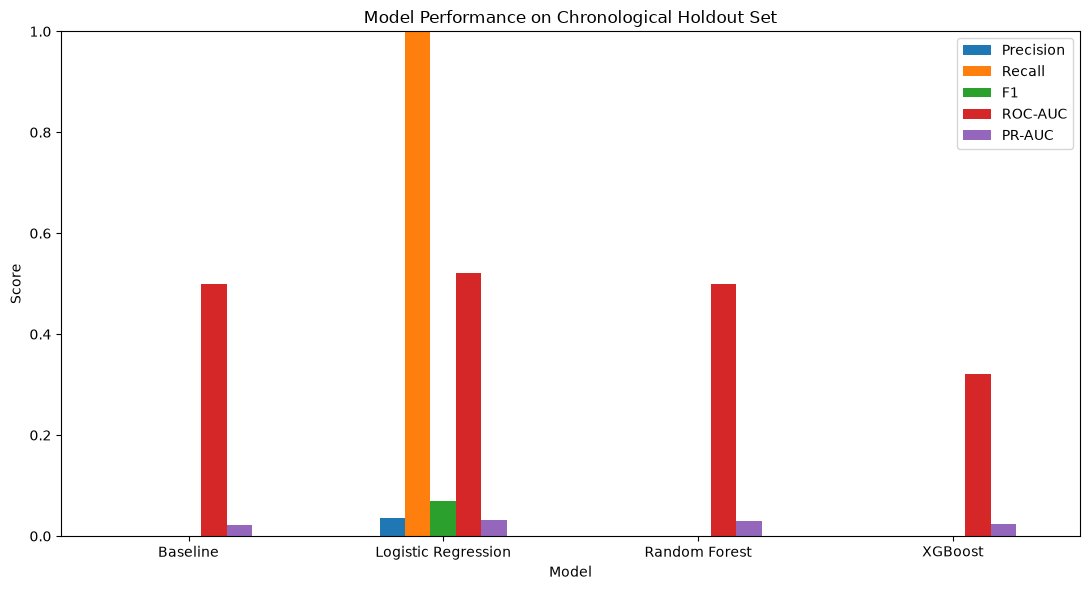

In [11]:
holdout_results[
    ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Model Performance on Chronological Holdout Set")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="best")

plt.tight_layout()
plt.show()


## 9. Confusion Matrices

Confusion matrices show the types of classification errors directly. This is particularly useful for recession forecasting because false negatives and false positives have different interpretations.


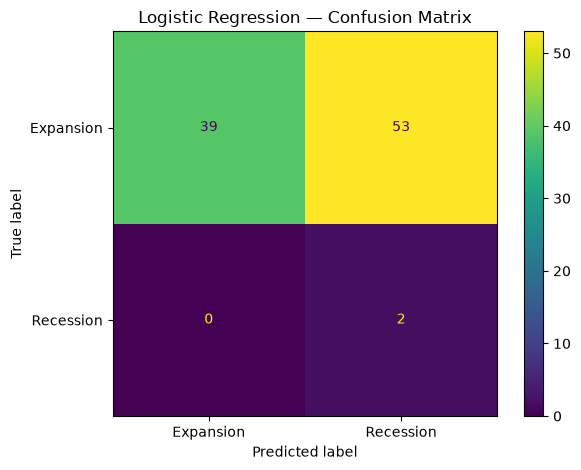

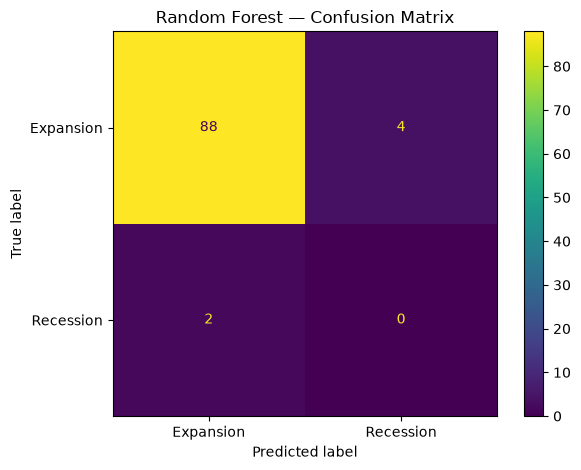

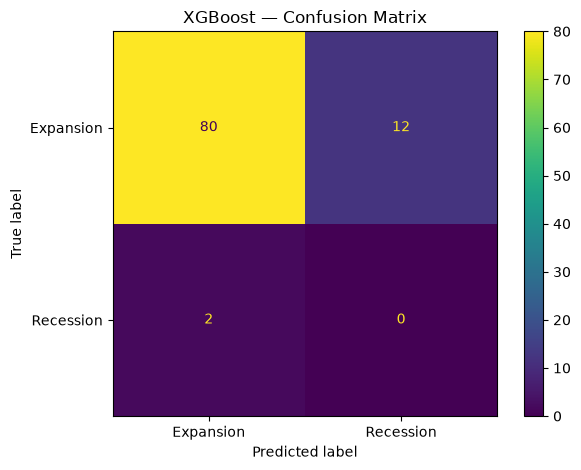

In [12]:
models_predictions = {
    "Logistic Regression": logistic_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred
}

for name, predictions in models_predictions.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Expansion", "Recession"]
    )
    plt.title(f"{name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()


## 10. Predicted Recession Probabilities

The models output probabilities in addition to binary predictions. Plotting these probabilities over time helps show when each model perceived elevated recession risk.


In [13]:
probabilities = pd.DataFrame(
    {
        "Actual recession": y_test,
        "Logistic Regression": logistic_prob,
        "Random Forest": rf_prob,
        "XGBoost": xgb_prob
    },
    index=X_test.index
)

probabilities.head()


,Actual recession,Logistic Regression,Random Forest,XGBoost
2018-04-01,0,0.080758,0.000,0.000318
2018-05-01,0,0.069364,0.014,0.000721
2018-06-01,0,0.328480,0.014,0.000891
2018-07-01,0,0.213717,0.020,0.000437
2018-08-01,0,0.133075,0.016,0.000473


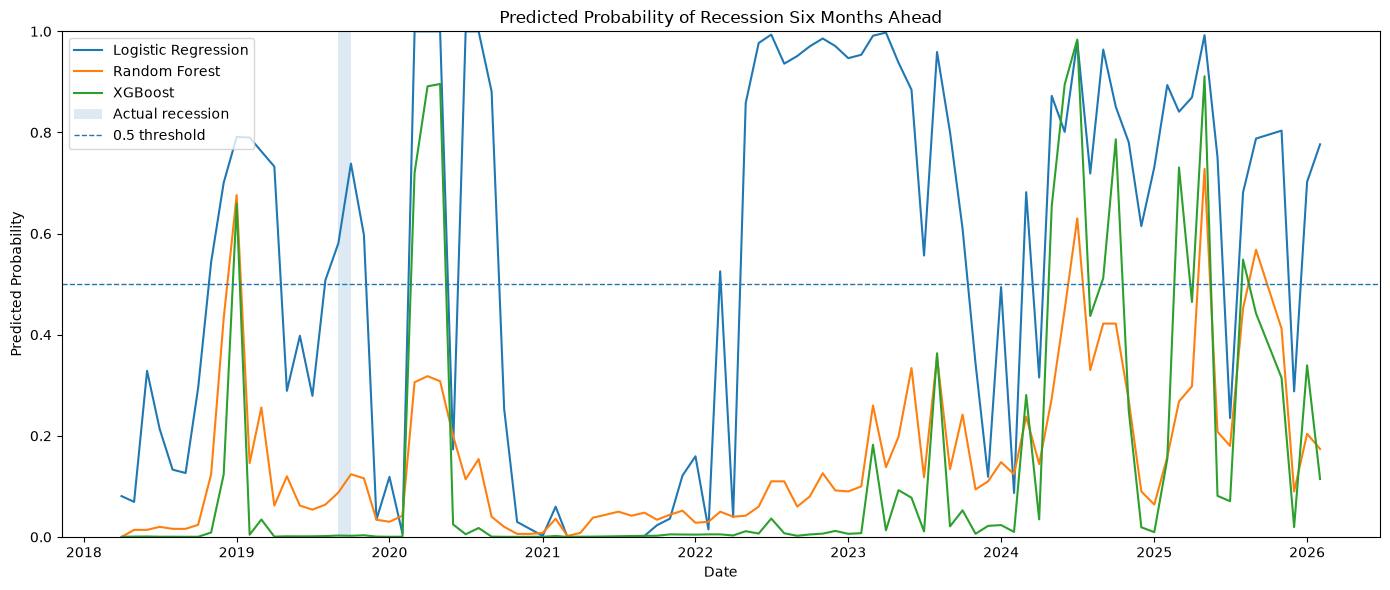

In [14]:
plt.figure(figsize=(14, 6))

plt.plot(
    probabilities.index,
    probabilities["Logistic Regression"],
    label="Logistic Regression"
)

plt.plot(
    probabilities.index,
    probabilities["Random Forest"],
    label="Random Forest"
)

plt.plot(
    probabilities.index,
    probabilities["XGBoost"],
    label="XGBoost"
)

plt.fill_between(
    probabilities.index,
    0,
    1,
    where=probabilities["Actual recession"].astype(bool),
    alpha=0.15,
    label="Actual recession"
)

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1,
    label="0.5 threshold"
)

plt.title("Predicted Probability of Recession Six Months Ahead")
plt.xlabel("Date")
plt.ylabel("Predicted Probability")
plt.ylim(0, 1)
plt.legend()

plt.tight_layout()
plt.show()


## 11. Time-Series Cross-Validation

A single train/test split can be sensitive to the particular recession episodes included in the test period. Time-series cross-validation provides a broader evaluation while maintaining temporal ordering.

Each fold trains on earlier observations and validates on a later block. No future observations are used to train a model that predicts the past.

Because some early validation folds may contain very few recession months, the fold-level results should be interpreted alongside the chronological holdout results.


In [15]:
tscv = TimeSeriesSplit(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(tscv.split(X), start=1):
    print(
        f"Fold {fold}: "
        f"train {X.index[train_idx[0]].date()} → {X.index[train_idx[-1]].date()} | "
        f"validation {X.index[val_idx[0]].date()} → {X.index[val_idx[-1]].date()} | "
        f"validation recessions = {int(y.iloc[val_idx].sum())}"
    )


Fold 1: train 1987-01-01 → 1993-07-01 | validation 1993-08-01 → 2000-01-01 | validation recessions = 0
Fold 2: train 1987-01-01 → 2000-01-01 | validation 2000-02-01 → 2006-07-01 | validation recessions = 8
Fold 3: train 1987-01-01 → 2006-07-01 | validation 2006-08-01 → 2013-01-01 | validation recessions = 18
Fold 4: train 1987-01-01 → 2013-01-01 | validation 2013-02-01 → 2019-07-01 | validation recessions = 0
Fold 5: train 1987-01-01 → 2019-07-01 | validation 2019-08-01 → 2026-02-01 | validation recessions = 2


The expanding-window cross-validation routine is imported from `src/evaluation.py`. It skips folds where the training or validation target contains only one class, because the full set of classification metrics would not be meaningful there.


In [16]:
# time_series_cv expects each builder to accept the fold's training target.
logistic_builder = lambda y_fold: build_logistic_model()
rf_builder = lambda y_fold: build_random_forest_model()
xgb_builder = lambda y_fold: build_xgboost_model(y_fold)


In [17]:
logistic_cv = time_series_cv(
    "Logistic Regression", logistic_builder, X, y
)
rf_cv = time_series_cv(
    "Random Forest", rf_builder, X, y
)
xgb_cv = time_series_cv(
    "XGBoost", xgb_builder, X, y
)

cv_results = pd.concat(
    [logistic_cv, rf_cv, xgb_cv],
    ignore_index=True,
)

cv_results


Skipping fold 1: only one class present.
Skipping fold 4: only one class present.
Skipping fold 1: only one class present.
Skipping fold 4: only one class present.
Skipping fold 1: only one class present.
Skipping fold 4: only one class present.


,Model,Fold,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,2,0.0,0.000000,0.000000,0.641071,0.141112
1,Logistic Regression,3,0.0,0.000000,0.000000,0.732407,0.346187
2,Logistic Regression,5,0.0,0.000000,0.000000,0.355263,0.029285
3,Random Forest,2,0.0,0.000000,0.000000,0.793750,0.244583
4,Random Forest,3,1.0,0.111111,0.200000,0.937037,0.814989
5,Random Forest,5,0.0,0.000000,0.000000,0.148026,0.022282
6,XGBoost,2,0.0,0.000000,0.000000,0.520536,0.112100
7,XGBoost,3,1.0,0.166667,0.285714,0.950926,0.835503
8,XGBoost,5,0.0,0.000000,0.000000,0.171053,0.022990


### Average Cross-Validation Performance


In [18]:
cv_summary = summarize_cv(cv_results)
cv_summary


## 12. Classification Reports on the Holdout Set


In [19]:
for name, predictions in models_predictions.items():
    print("\n", "=" * 60)
    print(name)
    print("=" * 60)
    print(
        classification_report(
            y_test,
            predictions,
            target_names=["Expansion", "Recession"],
            zero_division=0
        )
    )



Logistic Regression
              precision    recall  f1-score   support

   Expansion       1.00      0.42      0.60        92
   Recession       0.04      1.00      0.07         2

    accuracy                           0.44        94
   macro avg       0.52      0.71      0.33        94
weighted avg       0.98      0.44      0.58        94


Random Forest
              precision    recall  f1-score   support

   Expansion       0.98      0.96      0.97        92
   Recession       0.00      0.00      0.00         2

    accuracy                           0.94        94
   macro avg       0.49      0.48      0.48        94
weighted avg       0.96      0.94      0.95        94


XGBoost
              precision    recall  f1-score   support

   Expansion       0.98      0.87      0.92        92
   Recession       0.00      0.00      0.00         2

    accuracy                           0.85        94
   macro avg       0.49      0.43      0.46        94
weighted avg       0.95      

## 13. Modeling Notes

The model comparison should not be reduced to a single accuracy score. Recession forecasting is an imbalanced classification problem, and the models may trade off false alarms against missed recessions differently.

The chronological holdout set provides a realistic final-period test, while time-series cross-validation shows how performance varies across different historical periods.

The next notebook will interpret the fitted models, examine which features contribute most strongly to their predictions, and discuss the economic meaning and limitations of the results.

An important limitation remains that the project uses currently available historical FRED observations. It does not reconstruct the exact data vintages or publication delays that would have been available to a forecaster in real time.
